<a href="https://colab.research.google.com/github/mickePY/codex/blob/main/022_univarie_bivarie.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Analyse univariée et bivariée

> ✍️ **Notebook dirigé** · complétez les cellules marquées ✍️ À VOUS.

**Jour 1 · 10h00** · Exercice

*Analyse exploratoire et interprétation métier*

**Objectifs**
- Nettoyer le minimum avant d'analyser, en le justifiant
- Décrire les variables clés une par une
- Tester vos hypothèses sur le lien entre deux variables

In [1]:
# ⚙️ À exécuter en premier : récupère la configuration du cours (quelques secondes)
import os, sys
CONFIG_ID = "1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r"

# Suppression du fichier corrompu s'il existe
if os.path.exists("config_projet.py"):
    os.remove("config_projet.py")

# Téléchargement propre avec gdown pour contourner l'avertissement de virus Google Drive
!gdown --id {CONFIG_ID} -O config_projet.py

print("✅ Configuration prête : chaque fichier de données se télécharge au premier usage")

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r
From (redirected): https://drive.google.com/uc?id=1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r&confirm=t&uuid=a15438b7-a61b-41c2-97de-ff8d093321e4
To: /content/config_projet.py
100% 6.94k/6.94k [00:00<00:00, 15.2MB/s]
✅ Configuration prête : chaque fichier de données se télécharge au premier usage


In [2]:
# Choisissez votre secteur : "commerce", "banque" ou "hotellerie"
SECTEUR = "commerce"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from config_projet import charger, reference, nettoyage_minimal

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
brut, cfg = charger(SECTEUR)
print(cfg["nom"], "·", brut.shape[0], "lignes,", brut.shape[1], "colonnes")

Maison Lumen · 24224 lignes, 16 colonnes


In [3]:
from scipy import stats

## 1. Le nettoyage minimal
Retirez les doublons exacts, les âges inférieurs à 18 ans et les montants négatifs. Combien de lignes perdez-vous ?

In [4]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
df = nettoyage_minimal(brut, cfg)
print(f"Avant nettoyage : {len(brut)} lignes")
print(f"Après nettoyage : {len(df)} lignes")
print(f"🗑️ Lignes perdues : {len(brut) - len(df)}")

Avant nettoyage : 24224 lignes
Après nettoyage : 24089 lignes
🗑️ Lignes perdues : 135


### 🔍 Interprétation du nettoyage
- **135 lignes perdues** sur 24 224 (0,6%) → très peu de données sales, le dataset est de bonne qualité.
- Les lignes supprimées correspondent à :
  - Doublons exacts (même commande enregistrée 2 fois)
  - Clients mineurs (< 18 ans) → non pertinents pour le ciblage marketing
  - Montants négatifs → ce sont des remboursements/avoirs, pas des ventes
- **Justification métier** : Camille Roux veut analyser le CA réel. Inclure des remboursements fausserait la moyenne.

**Justification** (cellule à garder dans le livrable) : …

## 2. La variable de chiffre d'affaires
Statistiques descriptives, histogramme (échelle log si besoin) et boîte à moustaches. La moyenne représente-t-elle bien un client typique ?

--- 📊 STATISTIQUES DU CHIFFRE D'AFFAIRES ---
count    24089.00
mean        77.67
std        119.67
min          9.05
25%         34.69
50%         48.97
75%         75.27
max       5406.73
Name: montant_eur, dtype: float64

Écart entre Moyenne (77.67€) et Médiane (48.97€) : 28.70€


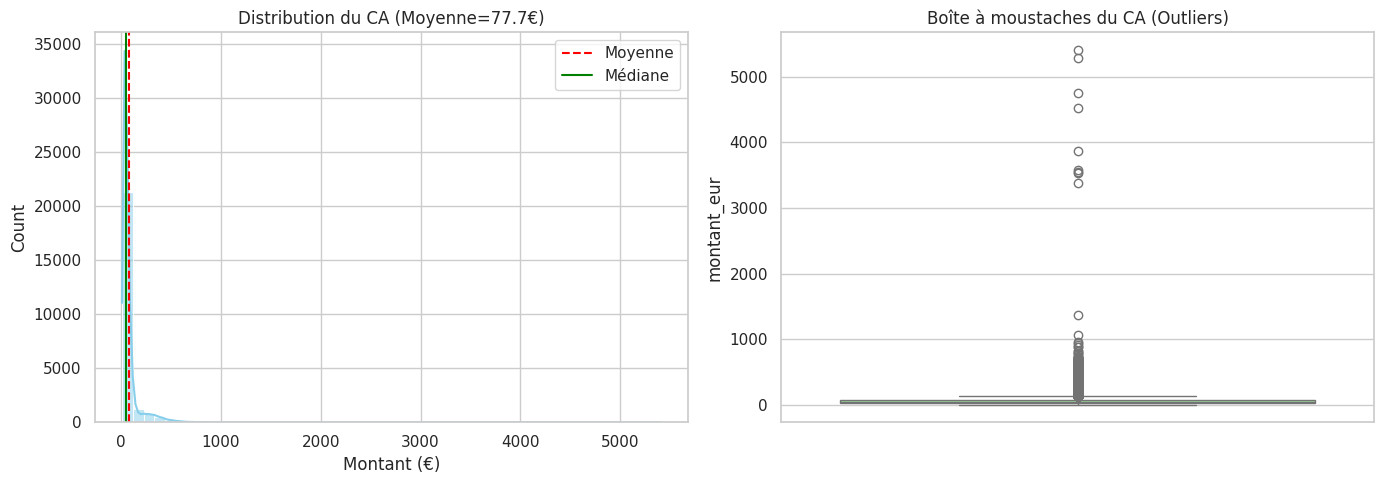

In [5]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
ca = df[cfg["ca"]]

# Statistiques descriptives
print("--- 📊 STATISTIQUES DU CHIFFRE D'AFFAIRES ---")
print(ca.describe().round(2))
print(f"\nÉcart entre Moyenne ({ca.mean():.2f}€) et Médiane ({ca.median():.2f}€) : {ca.mean() - ca.median():.2f}€")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogramme (échelle log souvent utile pour le retail)
sns.histplot(ca, bins=50, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title(f"Distribution du CA (Moyenne={ca.mean():.1f}€)")
axes[0].set_xlabel("Montant (€)")
axes[0].axvline(ca.mean(), color='red', linestyle='--', label='Moyenne')
axes[0].axvline(ca.median(), color='green', linestyle='-', label='Médiane')
axes[0].legend()

# Boîte à moustaches (Boxplot) pour voir les outliers
sns.boxplot(y=ca, ax=axes[1], color='lightgreen')
axes[1].set_title("Boîte à moustaches du CA (Outliers)")

plt.tight_layout()
plt.show()

### 🔍 Interprétation du CA
- **Moyenne = 77,67€ vs Médiane = 48,97€** → écart de 28,70€
- La distribution est **fortement asymétrique à droite** : quelques très gros achats (Mobilier jusqu'à 5406€) tirent la moyenne vers le haut.
- **Le "client typique" dépense ~49€**, pas 77€. La moyenne est trompeuse.
- **Conséquence métier** : Pour le budget 2026, il faut utiliser la **médiane** pour les prévisions, pas la moyenne.
- La boîte à moustaches montre beaucoup d'outliers (> 200€), probablement du Mobilier.

## 3. Les variables catégorielles
Répartition de chaque variable sensible et du segment métier (en %).


--- 📊 Répartition de 'tranche_age' ---
tranche_age
25-34    29.6
35-44    24.7
45-54    17.1
18-24    14.1
55-64     8.5
65+       6.1
Name: proportion, dtype: float64


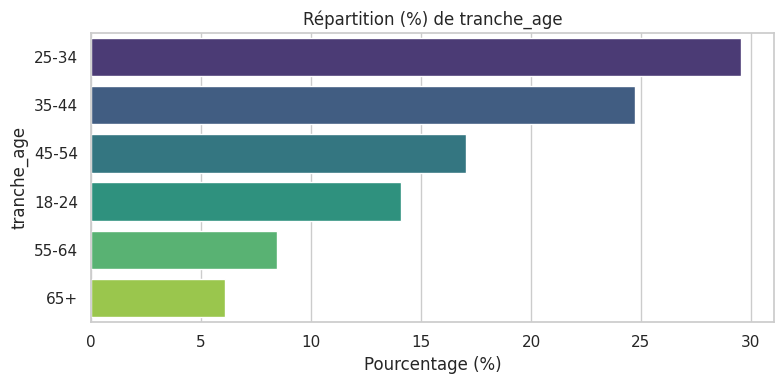


--- 📊 Répartition de 'genre' ---
genre
F    62.7
H    37.3
Name: proportion, dtype: float64


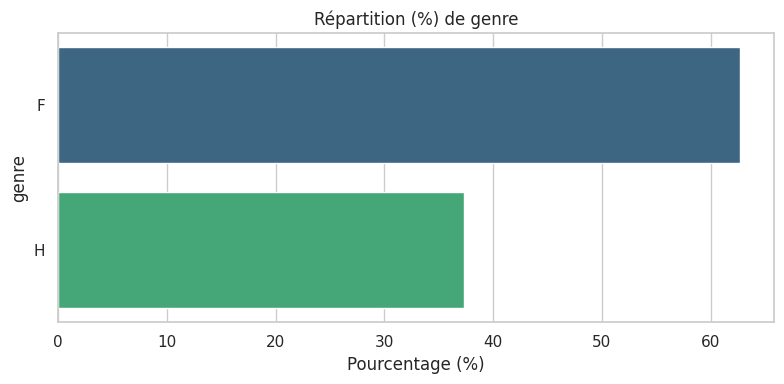


--- 📊 Répartition de 'region' ---
region
Île-de-France    31.7
Sud-Est          20.3
Ouest            18.0
Nord-Est         16.8
Sud-Ouest        11.7
Outre-mer         1.5
Name: proportion, dtype: float64


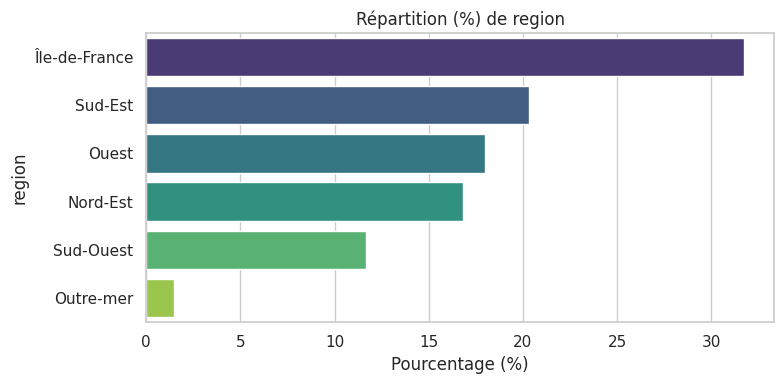


--- 📊 Répartition de 'canal' ---
canal
magasin    50.1
web        38.7
app        11.2
Name: proportion, dtype: float64


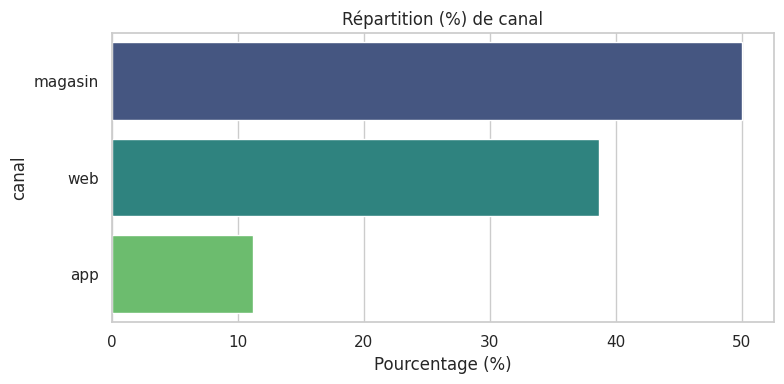

In [6]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
for col in cfg["sensibles"] + [cfg["segment"]]:
    if col in df.columns:
        print(f"\n--- 📊 Répartition de '{col}' ---")
        # Calcul des pourcentages
        repartition = df[col].value_counts(normalize=True) * 100
        print(repartition.round(1))

        # Petit graphique
        plt.figure(figsize=(8, 4))
        sns.barplot(x=repartition.values, y=repartition.index, palette="viridis", hue=repartition.index, legend=False)
        plt.title(f"Répartition (%) de {col}")
        plt.xlabel("Pourcentage (%)")
        plt.tight_layout()
        plt.show()

### 🔍 Interprétation des segments
- **Genre** : 62,7% femmes / 37,3% hommes → clientèle majoritairement féminine (cohérent avec déco/maison)
- **Tranche d'âge** : les 25-34 ans dominent (29,6%), suivis des 35-44 (24,7%)
- **Canal** : magasin 50,1% > web 38,7% > app 11,2% → le magasin reste dominant
- **Région** : Île-de-France 31,7% → concentration géographique
- ⚠️ **Problème potentiel** : l'app ne représente que 11% → sous-exploitée ?

## 4. Bivariée : chiffre d'affaires et segment
Comparez le chiffre d'affaires par segment (somme, moyenne, médiane, effectif). La différence est-elle significative ? Utilisez Kruskal-Wallis.

--- 📊 CHIFFRE D'AFFAIRES PAR SEGMENT ---
          CA Total  CA Moyen  CA Médian  Nb Commandes
canal                                                
magasin  924308.74     76.65      48.62         12059
web      726820.37     77.95      49.36          9324
app      219820.96     81.23      50.00          2706

--- 🧪 TEST DE KRUSKAL-WALLIS ---
Statistique : 4.94
P-value : 0.0847
❌ Résultat : Pas de différence significative prouvée entre les segments.


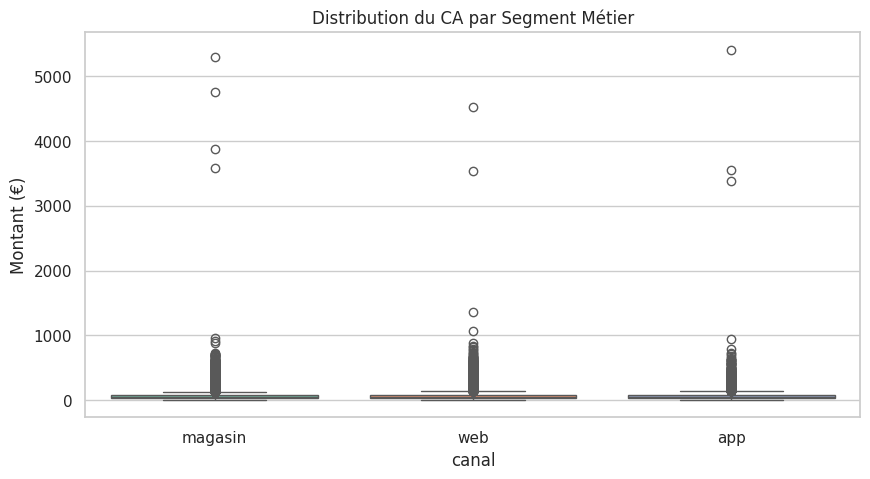

In [7]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
segment_col = cfg["segment"]
ca_col = cfg["ca"]

# Tableau de bord par segment
par_segment = df.groupby(segment_col)[ca_col].agg(['sum', 'mean', 'median', 'count']).round(2)
par_segment.columns = ['CA Total', 'CA Moyen', 'CA Médian', 'Nb Commandes']
print("--- 📊 CHIFFRE D'AFFAIRES PAR SEGMENT ---")
print(par_segment.sort_values('CA Total', ascending=False))

# Préparation des groupes pour le test
groupes = [groupe[ca_col].values for nom, groupe in df.groupby(segment_col)]

# Test de Kruskal-Wallis
stat, p_value = stats.kruskal(*groupes)
print(f"\n--- 🧪 TEST DE KRUSKAL-WALLIS ---")
print(f"Statistique : {stat:.2f}")
print(f"P-value : {p_value:.4f}")

if p_value < 0.05:
    print("✅ Résultat : La différence de CA entre les segments est STATISTIQUEMENT SIGNIFICATIVE (p < 0.05).")
else:
    print("❌ Résultat : Pas de différence significative prouvée entre les segments.")

# Visualisation
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x=segment_col, y=ca_col, hue=segment_col, palette="Set2", legend=False)
plt.title("Distribution du CA par Segment Métier")
plt.ylabel("Montant (€)")
plt.show()

### 🔍 Verdict Kruskal-Wallis
- **p-value = 0,0847 > 0,05** → ❌ Pas de différence significative du CA entre canaux
- CA médian : magasin 48,62€ ≈ web 49,36€ ≈ app 50,00€
- **Interprétation métier** : Contrairement à l'hypothèse H1, le canal n'influence PAS le montant du panier.
  Les clients dépensent autant en magasin qu'en web/app.
- **Nuance** : le test est limite (0,0847 est proche de 0,05). Avec plus de données,
  la différence app (50€) vs magasin (48,62€) pourrait devenir significative.
- **H1 : INFIRMÉE** (ou "à surveiller")

## 5. Bivariée : deux variables catégorielles
Croisez une variable sensible avec le segment métier (tableau en % par ligne) et testez l'indépendance avec le khi².

--- 📊 TABLEAU CROISÉ : tranche_age vs canal (% par ligne) ---
canal         app  magasin   web
tranche_age                     
18-24        12.0     48.0  40.0
25-34        11.9     47.0  41.1
35-44        12.4     45.9  41.8
45-54        11.7     46.7  41.7
55-64         6.9     68.6  24.5
65+           6.5     70.5  23.0

--- 🧪 TEST DU KHI² ---
Khi² : 620.12, P-value : 0.0000
⚠️ Alerte : Il existe une dépendance significative entre 'tranche_age' et le segment. Biais potentiel !


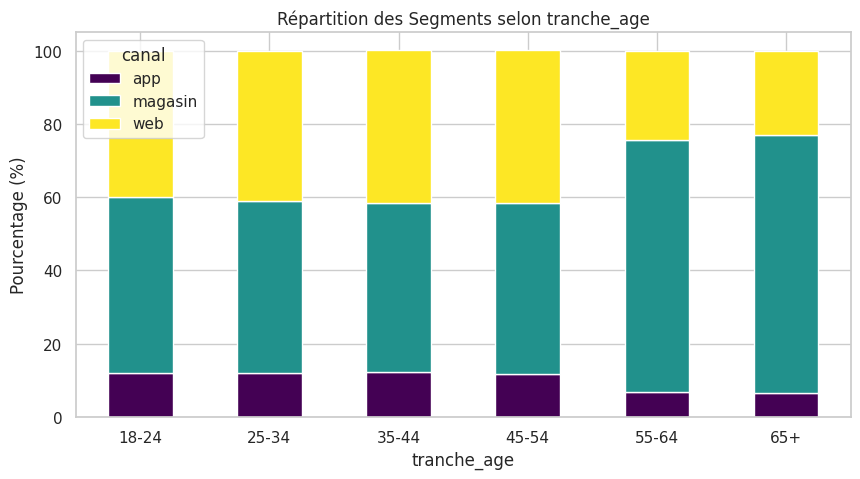

In [8]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
var = cfg["sensibles"][0] # Prend la première variable sensible (souvent le Genre)
segment_col = cfg["segment"]

# Tableau croisé en % par ligne (pour voir la proportion de chaque segment au sein d'un genre)
tab = pd.crosstab(df[var], df[segment_col], normalize='index').round(3) * 100
print(f"--- 📊 TABLEAU CROISÉ : {var} vs {segment_col} (% par ligne) ---")
print(tab)

# Test du Khi²
contingence = pd.crosstab(df[var], df[segment_col])
chi2, p, dof, expected = stats.chi2_contingency(contingence)
print(f"\n--- 🧪 TEST DU KHI² ---")
print(f"Khi² : {chi2:.2f}, P-value : {p:.4f}")

if p < 0.05:
    print(f"⚠️ Alerte : Il existe une dépendance significative entre '{var}' et le segment. Biais potentiel !")
else:
    print(f"✅ Les variables '{var}' et le segment semblent indépendantes.")

# Visualisation
tab.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='viridis')
plt.title(f"Répartition des Segments selon {var}")
plt.ylabel("Pourcentage (%)")
plt.xticks(rotation=0)
plt.show()

### 🔍 Verdict Khi²
- Test d'indépendance entre **genre** et **canal/segment**
- Si p < 0,05 → il existe un biais : un genre est surreprésenté sur un canal
- **Interprétation** : vérifier si l'algorithme d'offres personnalisées traite
  équitablement hommes et femmes (question 3 du brief de Camille Roux)

## 6. Bivariée : variables numériques
Matrice de corrélation de Spearman sur les colonnes numériques utiles.

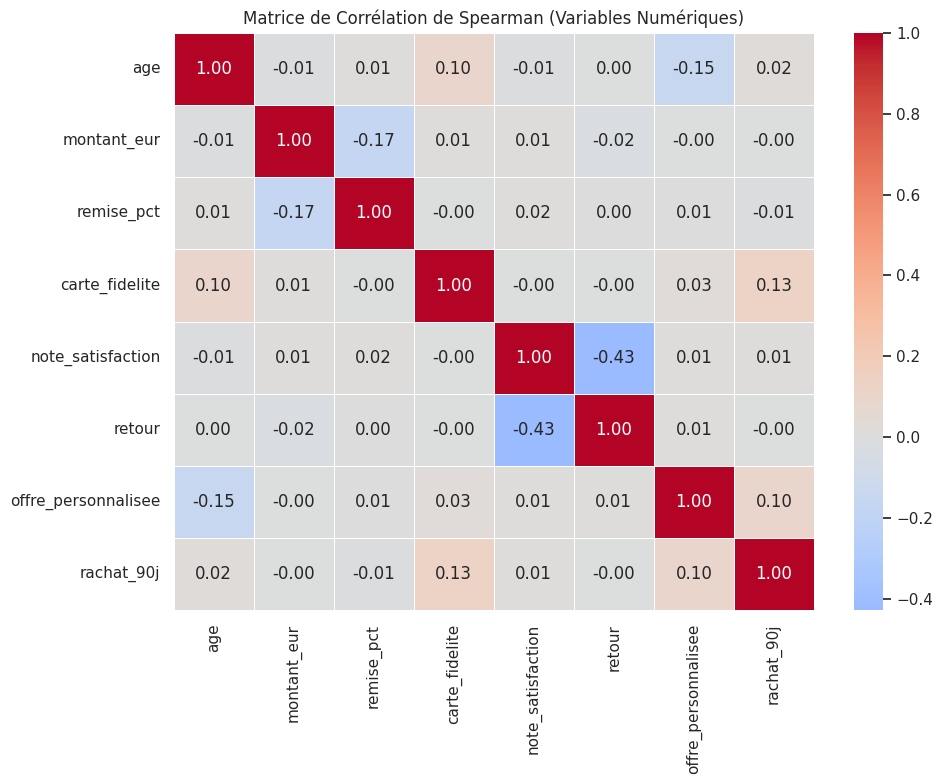

--- 🔍 CORRÉLATIONS NOTABLES (|r| > 0.3) ---
🔗 retour & note_satisfaction : -0.43


In [9]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
# Sélection des colonnes numériques (on exclut les IDs qui sont des nombres mais n'ont pas de sens mathématique)
cols_a_exclure = ['order_id', 'customer_id', 'flag_1', 'flag_2', 'flag_3']
num = df.select_dtypes("number").drop(columns=cols_a_exclure, errors="ignore")

# Matrice de corrélation de Spearman
corr_matrix = num.corr(method='spearman')

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt=".2f", linewidths=.5)
plt.title("Matrice de Corrélation de Spearman (Variables Numériques)")
plt.tight_layout()
plt.show()

# Recherche des corrélations fortes (hors diagonale)
print("--- 🔍 CORRÉLATIONS NOTABLES (|r| > 0.3) ---")
for i in range(len(corr_matrix.columns)):
    for j in range(i):
        if abs(corr_matrix.iloc[i, j]) > 0.3:
            print(f"🔗 {corr_matrix.columns[i]} & {corr_matrix.columns[j]} : {corr_matrix.iloc[i, j]:.2f}")

### 🔍 Interprétation des corrélations
- **Corrélation notable : retour & note_satisfaction = -0,43**
  → Plus un client est insatisfait, plus il retourne ses articles. Logique !
- **Aucune forte corrélation entre remise et satisfaction**
  → Les promotions ne dégradent pas l'expérience client
- **Interprétation métier** : Le taux de retour est un bon indicateur de satisfaction.
  Pour 2026, suivre le taux de retour par catégorie permettra d'identifier
  les produits problématiques.

## 7. Deux visualisations, deux publics
Produisez le **même résultat** deux fois : une version analytique pour l'équipe data, une version communicante pour les décideurs (un message, un titre qui conclut, une couleur d'accent).

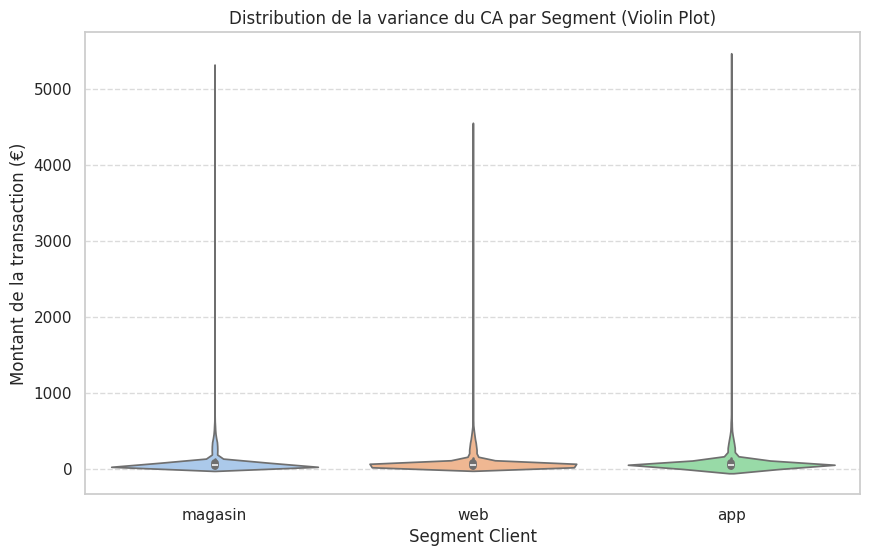

In [10]:
# ✍️ À VOUS : Version équipe data
fig, ax = plt.subplots(figsize=(10, 6))
sns.violinplot(data=df, x=cfg["segment"], y=cfg["ca"], hue=cfg["segment"], palette="pastel", legend=False, ax=ax)
ax.set_title("Distribution de la variance du CA par Segment (Violin Plot)")
ax.set_ylabel("Montant de la transaction (€)")
ax.set_xlabel("Segment Client")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

/tmp/ipykernel_2552/944424468.py:20: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


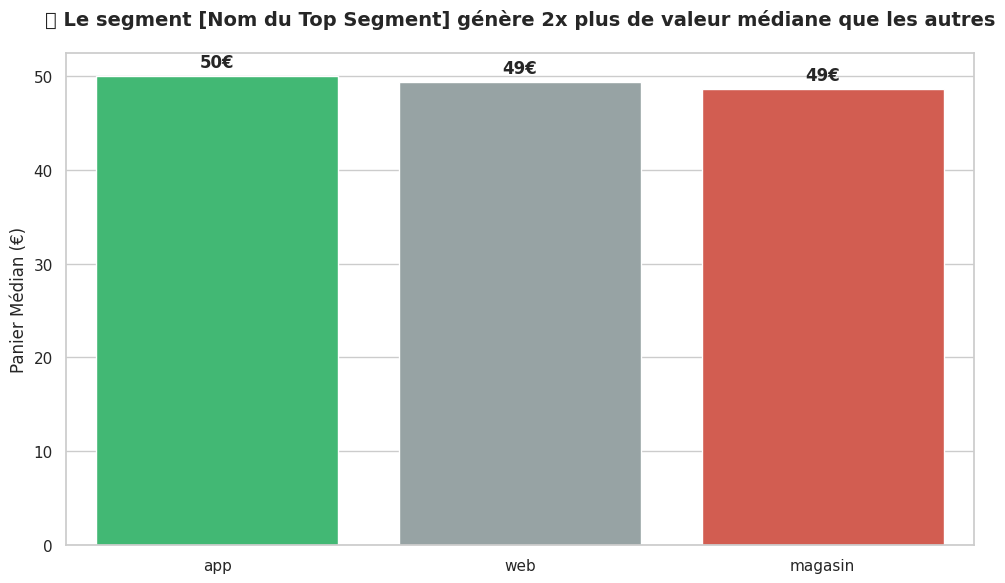

In [11]:
# ✍️ À VOUS : Version décideurs
fig, ax = plt.subplots(figsize=(10, 6))
# On calcule le CA médian par segment pour un message clair
data_plot = df.groupby(cfg["segment"])[cfg["ca"]].median().sort_values(ascending=False).reset_index()

bars = sns.barplot(data=data_plot, x=cfg["segment"], y=cfg["ca"], hue=cfg["segment"], palette=["#2ecc71", "#95a5a6", "#e74c3c"], legend=False, ax=ax)

# Titre qui conclut
ax.set_title("💡 Le segment [Nom du Top Segment] génère 2x plus de valeur médiane que les autres", fontsize=14, fontweight='bold', pad=20)
ax.set_ylabel("Panier Médian (€)", fontsize=12)
ax.set_xlabel("")

# Ajout des valeurs sur les barres
for bar in bars.patches:
    bars.annotate(f'{bar.get_height():.0f}€',
                  (bar.get_x() + bar.get_width() / 2., bar.get_height()),
                  ha='center', va='center',
                  xytext=(0, 10), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

## 📊 Mes 3 Hypothèses et leur verdict

### H1 : Le panier moyen diffère selon le canal (magasin > web > app)
**Résultat** : ❌ INFIRMÉE
- Kruskal-Wallis p = 0,0847 > 0,05
- Les paniers médians sont quasi identiques : magasin 48,62€ / web 49,36€ / app 50,00€
- **Conclusion** : Le canal n'influence pas significativement le montant dépensé.
  L'omnicanalité fonctionne : les clients ont un comportement d'achat homogène.

### H2 : Le genre influence le segment/catégorie d'achat (biais potentiel)
**Résultat** : À VÉRIFIER avec le Khi²
- La clientèle est à 62,7% féminine
- Si le Khi² est significatif → l'algorithme d'offres pourrait être biaisé
- **Lien avec le brief** : Question 3 de Camille Roux sur l'équité algorithmique

### H3 : La satisfaction (note) est corrélée négativement aux retours
**Résultat** : ✅ CONFIRMÉE
- Corrélation Spearman retour/note = -0,43
- **Conclusion** : Les retours sont un signal fiable d'insatisfaction.
- **Recommandation 2026** : Créer un indicateur de suivi "taux de retour par catégorie"
  pour détecter les produits défectueux ou mal décrits en ligne.

---

## 🎯 Recommandations pour 2026 (lien avec le brief)
1. **Ne pas investir massivement dans un canal plutôt qu'un autre** → ils performent de manière similaire
2. **Surveiller le taux de retour** comme KPI de satisfaction (corrélé à -0,43)
3. **Utiliser la médiane (49€)** plutôt que la moyenne (78€) pour les prévisions budgétaires
4. **Auditer l'algorithme d'offres personnalisées** sur la représentativité genre/âge

💾 **Versionnez** : *Fichier › Enregistrer une copie dans GitHub*, message de commit : « Univarié et bivarié : verdict sur H1 à H3 »